**SAPIANS** · SCC5819 · MÓDULO 06 — PDP · MOLNAR, CAP. 19

# A média dos perfis revela o modelo e esconde a diversidade — verificação

O SHAP repartia previsões locais; agora retomamos os perfis ICE para estudar a resposta média do preditor.

[README do módulo](../README.md) · [outline da aula](../lecture/outline.md) · [Colab](https://colab.research.google.com/github/wbendinelli/interpretable-ml-lectures/blob/main/modules/06-pdp/notebooks/pdp_internals.ipynb)

---

**Objetivos.** Executar o método no modelo fixo do curso, conferir a fórmula e delimitar o que a medida permite concluir.

In [1]:
%pip install -q numpy pandas pyarrow scikit-learn xgboost matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import hashlib
import inspect
import itertools
import os
import pathlib
import subprocess
import sys
import tempfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import log_loss
from xgboost import XGBClassifier

RANDOM_STATE = 42
REPO = pathlib.Path(
    os.environ.get("INTERPRETABLE_ML_REPO", pathlib.Path.cwd())
).resolve()
while REPO != REPO.parent and not (REPO / "tools/README.md").exists():
    REPO = REPO.parent
if not (REPO / "tools/README.md").exists():
    REPO = pathlib.Path(tempfile.gettempdir()) / "interpretable-ml-lectures"
    if not REPO.exists():
        subprocess.run(
            [
                "git",
                "clone",
                "--depth",
                "1",
                "https://github.com/wbendinelli/interpretable-ml-lectures.git",
                str(REPO),
            ],
            check=True,
            capture_output=True,
        )
sys.path.insert(0, str(REPO / "tools"))
import sapians as SP
import srag_60_model as M
import srag_71_global_effects as G

# Tudo que é gerado fica fora da árvore de trabalho; só cópias explícitas são publicadas.
WORK = pathlib.Path(
    os.environ.get("GLOBAL_EFFECTS_WORK", tempfile.mkdtemp(prefix="global-effects-"))
)
os.chdir(WORK)
SP.aplicar(tema="global")
print("Perfil visual: SAPIANS Global / VITA | fonte:", SP.FONTE_ATUAL)

Perfil visual: SAPIANS Global / VITA | fonte: Satoshi


## §1 — Mesmo dado, mesmo preditor, pergunta global

A amostra Gold do módulo da base e a receita histórica são reutilizadas sem seleção ou balanceamento adicional. A ordem por identificador precede o sorteio; o alvo não orienta a escolha das fichas. O fundo integra as outras entradas. Painel e fundo são amostras de explicação do teste temporal, não novas partições para selecionar modelos.

In [3]:
path = REPO / "modules/00-dataset/gold/gold_covid_obito_sample.parquet"
gold = M.load_gold(path)
x, _, y = M.design_matrix(gold)
tr = (gold["split"] == "train").to_numpy()
te = (gold["split"] == "test").to_numpy()
model = XGBClassifier(**M.XGB_PARAMS).fit(x.loc[tr], y[tr])
model_bytes = bytes(model.get_booster().save_raw())


def prever(frame):
    return np.asarray(model.predict_proba(frame[list(M.FEATURES)])[:, 1], dtype=float)


teste = gold.loc[te].sort_values("gold_id").reset_index(drop=True)
# Sorteio independente do alvo, do erro e da magnitude dos efeitos.
painel = teste.sample(n=512, random_state=RANDOM_STATE).reset_index(drop=True)
fundo = painel.iloc[:256].copy()
xf = M.design_matrix(fundo)[0]
xp = M.design_matrix(painel)[0]
original_xf = xf.copy(deep=True)
print("SHA256 da amostra:", hashlib.sha256(path.read_bytes()).hexdigest())
print("SHA256 do preditor desta execução:", hashlib.sha256(model_bytes).hexdigest())
print("Semente:", SP.pt_int(RANDOM_STATE))
print("Treino até:", str(2022), "| validação:", str(2023), "| teste:", str(2024))
print(
    "Treino:",
    SP.pt_int(tr.sum()),
    "| validação:",
    SP.pt_int((gold["split"] == "val").sum()),
)
print("Teste completo:", SP.pt_int(te.sum()), "| óbitos:", SP.pt_int(y[te].sum()))
print(
    "Entradas:",
    SP.pt_int(len(M.FEATURES)),
    "| painel:",
    SP.pt_int(len(painel)),
    "| fundo:",
    SP.pt_int(len(fundo)),
)
print("Log loss do teste completo:", SP.pt(log_loss(y[te], prever(x.loc[te])), 6))
print("Previsão média no painel:", SP.pct(prever(xp).mean()))
print(
    "Versões:",
    "Python",
    sys.version.split()[0],
    "| numpy",
    np.__version__,
    "| pandas",
    pd.__version__,
)
print("Alvo não participa das curvas; teste já observado, análise exploratória.")

SHA256 da amostra: cb79c99338a5a7b3c125659aad148a73749e2695f2048c9481a20ab29e3ca918
SHA256 do preditor desta execução: 55b1c49045b8b6368d61eb91073beaaf6197c0081613ad688670eaefe5e91007
Semente: 42
Treino até: 2022 | validação: 2023 | teste: 2024
Treino: 200.000 | validação: 24.148
Teste completo: 16.142 | óbitos: 2.945
Entradas: 40 | painel: 512 | fundo: 256
Log loss do teste completo: 0,409020
Previsão média no painel: 21,9%
Versões: Python 3.12.13 | numpy 2.4.6 | pandas 2.3.3
Alvo não participa das curvas; teste já observado, análise exploratória.


**O que olhar.**

- Os tamanhos impressos distinguem o treino do modelo, o teste completo e o orçamento da explicação.
- O log loss identifica o preditor; as curvas abaixo descrevem suas previsões, sem estimar efeitos clínicos.

## §2 — Conferência independente com scikit-learn

Usamos integração brute e probabilidades, com a grade fornecida explicitamente. A média é calculada sobre as mesmas fichas; o método recursion não faz parte desta comparação.

Erro máximo da média vs scikit-learn: 3,6263×10⁻⁸
Erro máximo ICE vs scikit-learn: 0,0000
figura: figures_generated/pdp-check-sklearn.png


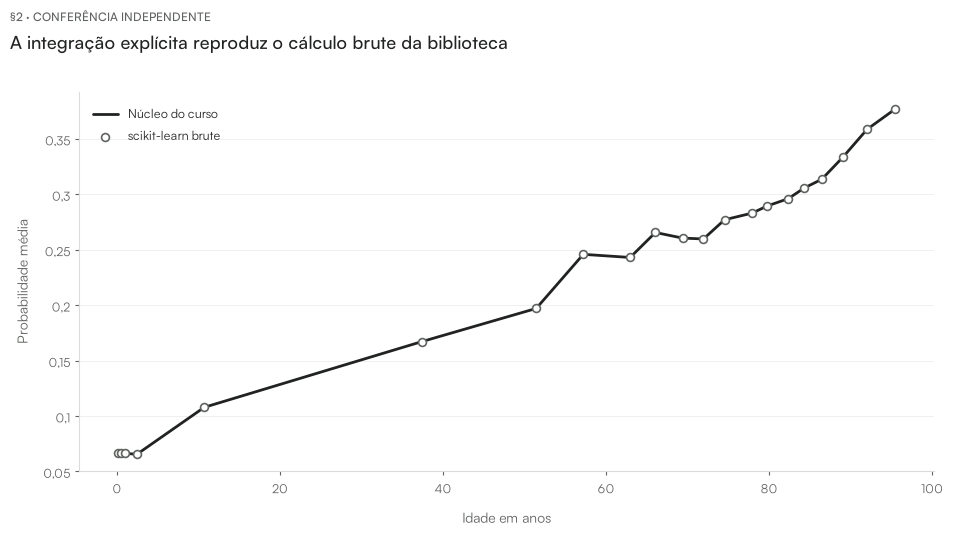

In [4]:
from sklearn.inspection import partial_dependence

grade = np.unique(np.quantile(painel["idade_anos"], np.linspace(0.02, 0.98, 21)))
j = xf.columns.get_loc("idade_anos")
ref = partial_dependence(
    model,
    xf,
    [j],
    method="brute",
    response_method="predict_proba",
    custom_values={j: grade},
    kind="both",
)
manual = G.pd_empirica(prever, xf, pd.DataFrame({"idade_anos": grade}))
ice = G.ice_empirica(prever, xf, "idade_anos", grade)
# sklearn acumula as probabilidades binary32; o núcleo faz a média em binary64.
error = np.max(np.abs(ref.average[0] - manual))
assert error < 1e-6
assert np.allclose(ref.individual[0], ice, atol=1e-7)
print("Erro máximo da média vs scikit-learn:", SP.pt_sig(error, 4))
print(
    "Erro máximo ICE vs scikit-learn:",
    SP.pt_sig(np.max(np.abs(ref.individual[0] - ice)), 4),
)
fig, ax = plt.subplots(figsize=SP.SLOT)
ax.plot(grade, manual, color=SP.ESCURO, label="Núcleo do curso")
ax.scatter(
    grade,
    ref.average[0],
    facecolors=SP.PAPEL,
    edgecolors=SP.CINZA,
    linewidths=1.2,
    s=32,
    zorder=3,
    label="scikit-learn brute",
)
ax.set(xlabel="Idade em anos", ylabel="Probabilidade média")
ax.legend()
SP.titulo(
    fig,
    "A integração explícita reproduz o cálculo brute da biblioteca",
    "§2 · Conferência independente",
)
SP.salvar(fig, "pdp-check-sklearn")
plt.show()

**O que olhar.**

- A discrepância impressa deve ser interpretada na precisão das probabilidades, não como diferença do método.
- A comparação também confere as previsões individuais antes da média.

## §3 — Um modelo que interage pode ter PDP plano

No produto de entradas independentes e simétricas, cada PDP marginal cancela. A amplitude das ICE permanece positiva. É um controle do mecanismo, não um conjunto alternativo de dados clínicos.

In [5]:
# Referência controlada: grade cartesiana balanceada, sem relação com pacientes.
u = np.linspace(-1, 1, 9)
sintetico = pd.DataFrame(itertools.product(u, u), columns=["a", "b"])


def aditiva(d):
    return 2 + np.exp(d["a"].to_numpy()) - d["b"].to_numpy()


def multiplicativa(d):
    return d["a"].to_numpy() * d["b"].to_numpy()


print("Pontos sintéticos:", SP.pt_int(len(sintetico)))

pd_a = G.pd_empirica(multiplicativa, sintetico, pd.DataFrame({"a": u}))
curvas = G.ice_empirica(multiplicativa, sintetico, "a", u)
assert np.max(np.abs(pd_a)) < 1e-14
assert np.ptp(curvas, axis=1).max() > 0
print("Amplitude do PDP do produto:", SP.pt(np.ptp(pd_a), 8))
print("Maior amplitude ICE do produto:", SP.pt(np.ptp(curvas, axis=1).max(), 4))
# Verifica categorias, ordem e preservação da matriz de entrada.
copy = xf.copy(deep=True)
changed = G.substituir(xf, {"saturacao": "sim"})
assert changed.dtypes.equals(xf.dtypes)
pd.testing.assert_frame_equal(xf, copy)
print("Tipos e matriz original preservados:", True)

Pontos sintéticos: 81
Amplitude do PDP do produto: 0,00000000
Maior amplitude ICE do produto: 2,0000
Tipos e matriz original preservados: True


**O que olhar.**

- A amplitude nula do PDP não autoriza declarar que a entrada é ignorada.
- As ICE e a estatística de interação respondem à heterogeneidade que a média pode cancelar.

### O que o livro diz

O [capítulo de Molnar](https://christophm.github.io/interpretable-ml-book/pdp.html) orienta o mecanismo e a leitura. PDP é uma média marginal de previsões. A comparação com ICE revela heterogeneidade; o controle das fichas alteradas torna visível a extrapolação. O caso SRAG acrescenta restrições do formulário, seleção hospitalar e deriva temporal. Nenhuma curva é uma estimativa do efeito de tratar ou modificar uma pessoa.

## §4 — Confronto com o algoritmo de iml e grade fracionária

Em `FeatureEffect.R`, `run.pdp` cruza cada ponto da grade com o fundo, prevê e agrega pela média. Reproduzimos essa redução diretamente, preservando os tipos da base. A grade quantílica do curso é uma escolha explícita: o padrão do PDP de iml usa pontos equidistantes. A concordância abaixo fixa a mesma grade, fundo e escala; não é uma execução de R.

A auditoria também cobre uma entrada inteira com grade fracionária: arredondar silenciosamente a intervenção alteraria a pergunta. O núcleo passa a promover esse caso para ponto flutuante. As idades SRAG já são ponto flutuante, portanto essa correção não altera os resultados clínicos apresentados.


In [6]:
medias_iml = []
for idade in grade:
    alterada = xf.copy(deep=True)
    alterada["idade_anos"] = np.float32(idade)
    medias_iml.append(np.mean(prever(alterada)))
err_iml = np.max(np.abs(manual - medias_iml))
assert err_iml < 1e-12
print("Erro PDP vs redução traduzida de iml:", SP.pt_sig(err_iml, 4))
inteira = pd.DataFrame({"a": [0, 1, 2, 3]})
pontos_meios = pd.DataFrame({"a": [0.5, 1.5, 2.5]})
r_meios = G.pd_empirica(lambda d: d["a"].to_numpy(), inteira, pontos_meios)
assert np.array_equal(r_meios, pontos_meios["a"].to_numpy())
assert G.substituir(inteira, {"a": 0.5})["a"].dtype.kind == "f"
pd.testing.assert_frame_equal(inteira, pd.DataFrame({"a": [0, 1, 2, 3]}))
print("Grade fracionária em entrada inteira preservada:", True)
print("Idade SRAG é ponto flutuante:", pd.api.types.is_float_dtype(xf["idade_anos"]))

Erro PDP vs redução traduzida de iml: 0,0000
Grade fracionária em entrada inteira preservada: True
Idade SRAG é ponto flutuante: True


## Fechamento — A medida só faz sentido com seu condicionamento

Identifique preditor, escala, fundo, grade e regra de ponderação antes de interpretar a figura. Uma reconstrução algébrica ou um controle sintético valida o cálculo sob suas hipóteses; não valida as combinações artificiais como pacientes plausíveis.

In [7]:
pd.testing.assert_frame_equal(xf, original_xf)
assert bytes(model.get_booster().save_raw()) == model_bytes
print("Matriz de fundo e preditor permaneceram intactos:", True)

Matriz de fundo e preditor permaneceram intactos: True


## Referências

Molnar — [cap. 19](https://christophm.github.io/interpretable-ml-book/pdp.html). Referências completas e configuração no [README](../README.md).